data set trajectories Brownian particle in a moving potential



Per la simulazione vengono utilizzate le librerie per il calcolo matematico e per il Machine Learning.

In [ ]:
import numpy as np
import matplotlib as mp
from matplotlib import pyplot as pl
import math as mt
import sklearn
from sklearn.linear_model import LogisticRegression



Il primo passo è quello di creare le variabili discretizzando il tempo e il vettore λ(t), e inizializzare i parametri.

In [ ]:
#creo tutte le variabili necessarie
#tempi, lambda, variazione

t_i = 0
t_f = 10
lam_i = 0
lam_f = 5
u = (lam_f - lam_i)/t_f
step = 100
dt = (t_f - t_i)/step
dl = (lam_f-lam_i)/step

print('PARAMETRI DEL MOTO')
print('\ntempo: ', t_f)
print('dt: ', dt)
print('lambda: ', lam_f)
print('dl:', dl )
print('passi: ', step)

#parametri/costanti
kappa=1
gamma=1
beta=1


PARAMETRI DEL MOTO

tempo:  10
dt:  0.1
lambda:  5
dl: 0.05
passi:  100


Si creano i vettori necessari per costruire la simulazione del moto.

In [ ]:
#creo i vettori che serviranno
# per la simulazione del moto

time = np.arange(t_i, t_f, dt)
lam = np.arange(lam_i, lam_f, dl)

#print di controllo per verificare che le dimensioni dei vettori siano uguali
#(lambda evolve per ogni istante temporale)
print('dimensioni dei vettori: ', len(time), len(lam))

dimensioni dei vettori:  100 100


Si definisce la funzione per la soluzione dell'equazione differenziale. Dentro la funzione vengono inizializzati come vettori vuoti x(t), x_dot e w. Si inserisce la condizione sulla traiettorie forward o backward con un if-else. Con un ciclo for sui tempi si costruisce la singola traiettoria, iterando su n si genera l'insieme di traiettorie. Per generare le traiettorie backward viene cambiato il dato inizale e invertito il vettore λ. Conclusi i due cilci, le traiettorie vengono tutte invertite utilizzando la funzione flip.

In [ ]:
def traj(T, d_t, L, d_l , gam, bet, kap, N, frw):

  #inizializzo vettore posizione e vettore velocità
  #sto generando matrici di N(traiettorie) righe e T(istanti di tempo) colonne
  x=np.zeros((N,T.size))
  xdot=np.zeros((N,T.size))
  w=np.zeros(N)

  if frw == True:

    #estraggo dati iniziali con distrib Boltzman canonico mu=0 varianza=2
    #ora estraggo un valore per ogni traiettoria della matrice
    x[:,0]=np.random.normal(0,0.5,N)
    y=np.ones(N)


    #genero le traiettorie con due cicli for: uno scorre le righe (numero di traiettorie)
    #e uno scorre i tempi
    for n in range(N):
      for t in range(T.size - 1):
        #estraggo un valore di rumore termico gaussiano mu=0 sigma= rad(2/beta*gamma)
        Vrand=np.random.normal(0,np.sqrt(2/(beta*gamma)))/np.sqrt(dt)

        #faccio evolvere il sistema riempiendo il vettore come da equazione differenziale
        xdot[n,t] = -kap / gam * (x[n, t] - L[t]) + Vrand
        x[n , t + 1] = x[n, t] + dt  * xdot[n, t]

        #definisco il lavoro
        w[n]=w[n] + 0.5*kap*d_l*(-2*x[n,t]+L[t]+L[t+1])

  else:
    x[:,0]=np.random.normal(5,0.5,N)
    y=np.zeros(N)
    L=np.flip(L)

    for n in range(N):
      for t in range(T.size - 1):
        #estraggo un valore di rumore termico gaussiano mu=0 sigma= rad(2/beta*gamma)
        Vrand=np.random.normal(0,np.sqrt(2/(beta*gamma)))/np.sqrt(dt)

        #faccio evolvere il sistema riempiendo il vettore come da equazione differenziale
        xdot[n,t] = -kap / gam * (x[n, t] - L[t]) + Vrand
        x[n , t + 1] = x[n, t] + dt  * xdot[n, t]


#flip delle traiettorie e nuovo lavoro
    x=np.flip(x, axis=1)
    for n in range(N):
      for t in range(T.size-1):
        #definisco il lavoro
        w[n]=w[n] + 0.5*kap*d_l*(-2*x[n,t]+L[t]+L[t+1])

  for i in range(x.shape[0]):
      plot = pl.plot(T,x[i,:])

  return x, y, w


Uso la funzione per computare e graficare le traiettorie forward.

[1. 1. 1. ... 1. 1. 1.]


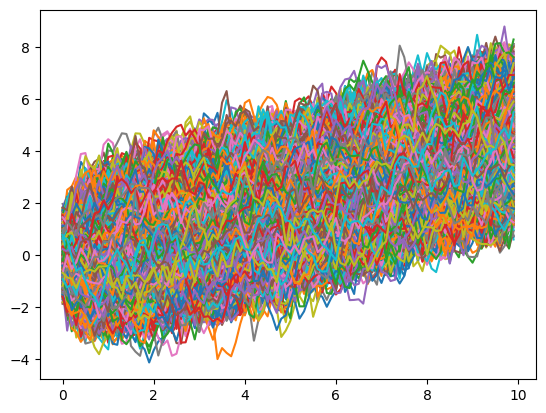

In [ ]:
#riempio due ogetti, il primo è la matrice delle traiettorie, il secondo è il grafico
traiettorie, etichette, lavoro = traj(time, dt, lam, dl, gamma, beta, kappa, 20000, frw=True)
print(etichette)

In [ ]:
print(traiettorie.shape)

(20000, 100)


Uso la funzione per computare e graficare le traiettorie backward.

[0. 0. 0. ... 0. 0. 0.]


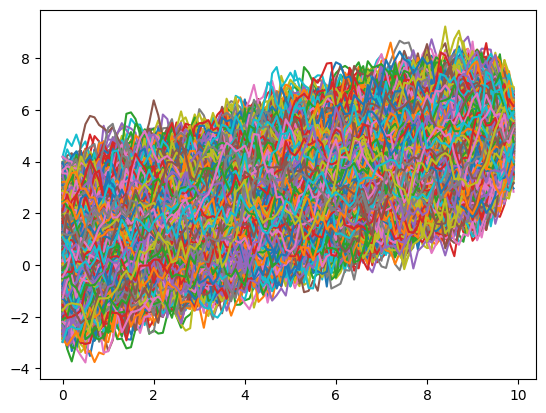

In [ ]:
#chiamo la funzione per le traiettorie backwards
traiettorie_b, etichette_b, lavoro_b = traj(time, dt, lam, dl, gamma, beta, kappa, 20000, frw=False)
print(etichette_b)

Genero il plot del lavoro riempiendo un istogramma.

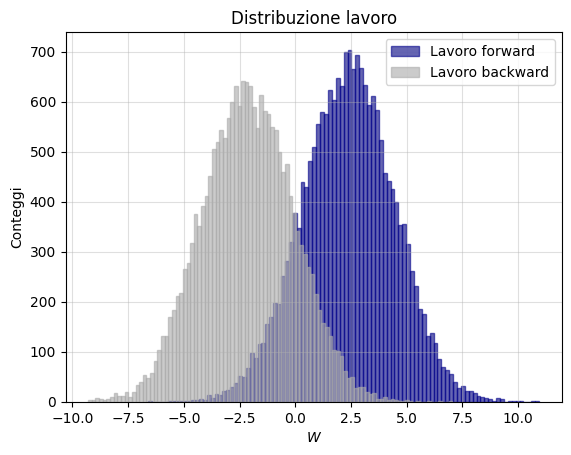

2.3568591506174608
-2.138357877849186


In [ ]:
#lavoro
pl.hist(lavoro, bins=100, edgecolor='darkblue', color='navy', label='Lavoro forward', alpha=0.6)
pl.hist(lavoro_b, bins=100, edgecolor='darkgrey', color='darkgrey',label='Lavoro backward',  alpha=0.6)
pl.legend()
pl.grid(alpha=0.4)
pl.xlabel(r'$W$')
pl.ylabel('Conteggi')
pl.title('Distribuzione lavoro')
pl.show()
print(lavoro.mean())
print(lavoro_b.mean())

Text(0.5, 1.0, 'Simulazione moto browniano')

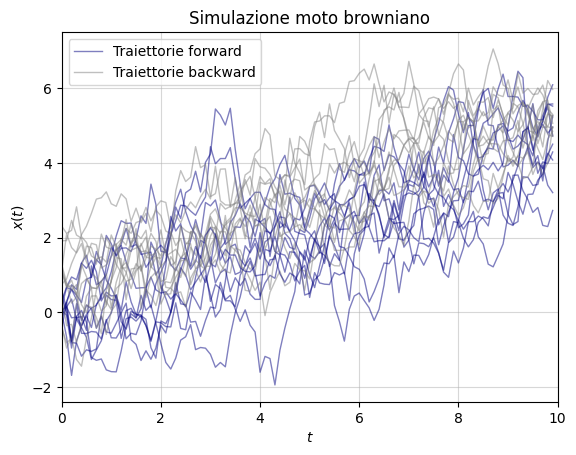

In [ ]:
#plot per avere dei grafici più chiari
fig,ax= pl.subplots()
ax.plot(time, traiettorie[0:10, :].T, linewidth= 1, color= 'navy', alpha=0.5)
ax.plot(time, traiettorie_b[0:10, :].T, linewidth= 1, color= 'grey', alpha=0.5)
ax.plot(time, traiettorie[11, :].T, linewidth= 1, color= 'navy', label= 'Traiettorie forward', alpha=0.5)
ax.plot(time, traiettorie_b[11, :].T, linewidth= 1, color= 'grey', label= 'Traiettorie backward', alpha=0.5)
ax.legend()
ax.grid(alpha=0.5)
ax.set_xlabel(r'$t$')
ax.set_ylabel(r'$x(t)$')
ax.set_xlim(0,10)
ax.set_title('Simulazione moto browniano')

Per preparare i dati per il ML, li unisco in una unica matrice e poi li permuto.

In [ ]:
#unisco i dati in una matrice unica e poi li permuto.
X=np.concatenate((traiettorie, traiettorie_b), axis=0)
Y=np.concatenate((etichette, etichette_b))
W=np.concatenate((lavoro, lavoro_b))

np.random.seed(19)
permutazione=np.random.permutation(X.shape[0]) #permuta una sequenza di numeri o range di numeri nel vett
X=X[permutazione] #matrice features
Y=Y[permutazione] #matrice labels
W=W[permutazione]

print(permutazione)
print(Y)


[26350 15649 27330 ... 34146 17141 10862]
[0. 1. 0. ... 0. 1. 1.]


Divido i dati tra quelli che il modello utilizzerà per il training e quelli che verranno utilizzati per il test.

In [ ]:
#divido i dati in due set
X_train=X[0:28000, :]
X_test=X[28001:, :]
Y_train=Y[0:28000]
Y_test=Y[28001:]
W_train=W[0:28000]
W_test=W[28001:]

#variabili per plot
W_plot=W[12001:13001]
X_plot=X[12001:13001, :]

Utilizzo i dati per il ML e stampo la precizsione nella previsione.

In [ ]:
#modello,fit,accuratezza
modello=LogisticRegression()
modello.fit(X_train, Y_train)
print('sono stata brava al', modello.score(X_test, Y_test))

sono stata brava al 0.9910825902158513


/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Calcolo i parametri pesi e intercetta.

In [ ]:
weights=modello.coef_
intercept=modello.intercept_

print('pesi', weights)
print('intercetta', intercept)

pesi [[ 0.18889021 -0.3541166  -0.22332713 -0.29143452  0.0517764  -0.38315751
  -0.99722145  0.25554313 -0.71205437  0.29698572 -0.81036481 -0.33203831
  -0.09944704 -0.01218254 -0.28142229 -0.42285445  0.43993528 -0.92374907
   0.05298215 -0.20396244 -0.77095374  0.02849485 -0.01219275 -0.31229891
  -0.48990095 -0.37811329 -0.13354713 -0.28923399 -0.33254133 -0.09275932
  -0.11826048 -0.54114842  0.06122715  0.21898085 -0.57237793 -0.30311554
  -0.50997674 -0.3884594  -0.24363191 -0.50109284  0.07678658 -0.32659499
   0.06755127 -0.48023532 -0.07539089 -0.35280098 -0.02218753 -0.6862617
  -0.36312098 -0.32269112  0.03438884 -0.05164534 -0.79406544 -0.47096247
   0.19010995 -0.04951272 -0.63507915  0.05129364 -0.4034703  -0.5938795
  -0.0240538  -0.31072259 -0.24449467  0.40372937 -0.24846084 -0.3183508
  -0.70063964  0.22447282 -0.75827348  0.0833327  -0.17459177 -0.75795687
   0.53758952 -1.07146734 -0.08327451  0.29923066 -0.31861482 -0.24670235
  -0.41731328 -0.07629807  0.3626943

Costruisco uno scatter plot dove metto a confronto la previsione del modello con i dati teorici.

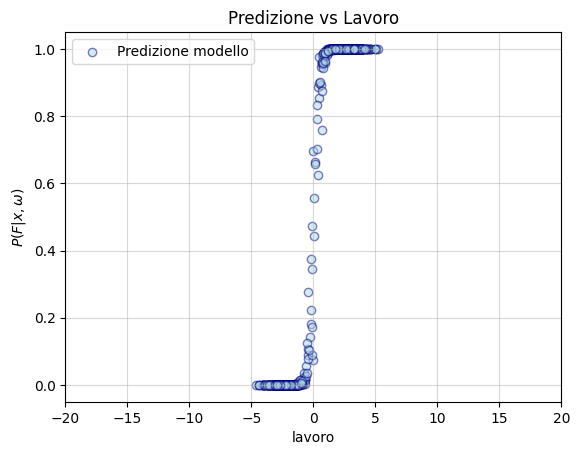

In [ ]:
#scatter plot
z=np.dot(weights, X_plot.T) +intercept
#print(z)
p=1/(1+np.exp(-z))

fig=pl.figure()
ax=fig.add_subplot(1,1,1)
ax.scatter(W_plot, p, alpha=0.5, c= 'lightblue', label='Predizione modello', edgecolor='navy')
ax.set_xlim(-20, 20)
ax.grid(alpha=0.5)
ax.set_xlabel('lavoro')
ax.set_ylabel(r'$P(F|x, \omega$)')
ax.set_title('Predizione vs Lavoro')
ax.legend()

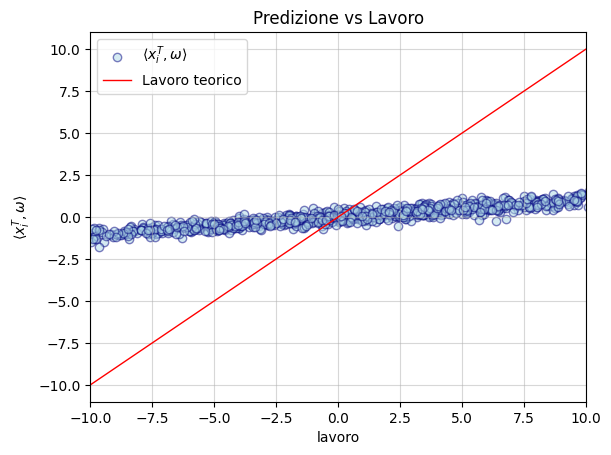

In [ ]:
fig=pl.figure()
ax=fig.add_subplot(1,1,1)
ax.scatter(W_plot, z, alpha=0.5, c= 'lightblue', label=r'$\langle x_i ^T, \omega \rangle$', edgecolor='navy')
ax.plot([-10,10], [-10,10], color='red', label='Lavoro teorico', linewidth=1)
ax.set_xlim(-10, 10)
ax.grid(alpha=0.5)
ax.set_xlabel('lavoro')
ax.set_ylabel(r'$\langle x_i ^T, \omega \rangle$')
ax.set_title('Predizione vs Lavoro')
ax.legend()

In [ ]:
#piccolo tentativo su una rete neurale
#rete neurale
# Aggiungiamo uno strato MaxPooling2D dopo quello convolutivo ed uno strato di Dropout dopo lo strato nascosto denso
model = tf.keras.models.Sequential([
    tf.keras.layers.Conv1D(4, 2, input_shape=(X.shape[1], 1), activation='relu'), #primo strato
    tf.keras.layers.Flatten(), #se hai una matrice lui vettorizza
    tf.keras.layers.Dense(20, activation='relu'),
    tf.keras.layers.Dropout(0.25),          # strato di dropout
    tf.keras.layers.Dense(2, activation='sigmoid')
])

model.compile(optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

model.fit(X_train, Y_train, epochs=20)
test_loss, test_accuracy = model.evaluate(X_test,  Y_test)
print('Test loss:\t ', test_loss)
print('Test accuracy:\t ', test_accuracy)

Epoch 1/20
375/375 [==============================] - 2s 2ms/step - loss: 0.5652 - accuracy: 0.7183
Epoch 2/20
375/375 [==============================] - 1s 2ms/step - loss: 0.4438 - accuracy: 0.7876
Epoch 3/20
375/375 [==============================] - 1s 2ms/step - loss: 0.3554 - accuracy: 0.8403
Epoch 4/20
375/375 [==============================] - 1s 2ms/step - loss: 0.3356 - accuracy: 0.8526
Epoch 5/20
375/375 [==============================] - 1s 2ms/step - loss: 0.3271 - accuracy: 0.8599
Epoch 6/20
375/375 [==============================] - 1s 2ms/step - loss: 0.3199 - accuracy: 0.8637
Epoch 7/20
375/375 [==============================] - 1s 2ms/step - loss: 0.3154 - accuracy: 0.8680
Epoch 8/20
375/375 [==============================] - 1s 2ms/step - loss: 0.3094 - accuracy: 0.8698
Epoch 9/20
375/375 [==============================] - 1s 2ms/step - loss: 0.3112 - accuracy: 0.8710
Epoch 10/20
375/375 [==============================] - 1s 3ms/step - loss: 0.3114 - accuracy: 0.8733